# 01 Data and index numbers: Bangladesh food prices

This notebook covers the BUS173 topic on index numbers. It uses WFP retail prices from Bangladeshi markets (cleaned by `src/clean.py`) to build monthly food price indices with Laspeyres, Paasche and Fisher formulas and a chain-linked Laspeyres. It then compares them with the official food CPI that FAOSTAT republishes from the Bangladesh Bureau of Statistics.

There are two baskets, because WFP's coverage changed:

- **Long basket** (Sep 2006 to Jul 2026): coarse rice, wheat flour (atta), masur lentils and palm oil. These four are the only items priced every month since 2006. Base year 2016 = 100.
- **Wide basket** (Sep 2024 to Mar 2026): the same four plus soybean oil, sugar, eggs, broiler chicken, onion, potato and green chili. Base year 2025 = 100.

Weights are monthly quantities per person from the BBS HIES intake table (HIES 2016 for the long basket, 2022 for the short one; see `src/indices.py` and `outputs/tables/index_weights.csv`). Every number used in the README goes to `outputs/tables/key_facts_indices.csv`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from plot_utils import *
import indices as ix
set_style()
prices = pd.read_parquet(PROC / "prices_monthly.parquet")
nat = pd.read_parquet(PROC / "national_prices.parquet")
div = pd.read_parquet(PROC / "division_prices.parquet")
L, S, D, W = ix.build()
facts = []
def fact(name, value, how):
    facts.append({"fact": name, "value": value, "how_computed": how})
    print(f"{name}: {value}")
r = prices[prices.pricetype == "Retail"]
fact("wfp_rows", len(prices), "Rows in prices_monthly.parquet (retail and wholesale)")
fact("wfp_first_month", str(prices.date.min().date())[:7], "Earliest WFP month")
fact("wfp_last_month", str(prices.date.max().date())[:7], "Latest WFP month")
fact("wfp_commodities", prices.commodity.nunique(), "Distinct WFP commodity labels")
fact("wfp_markets", prices.market.nunique(), "Distinct WFP markets")
fact("outliers_flagged", int(prices.outlier.sum()), "|robust z| > 5 within commodity-market (src/clean.py)")
pd.read_csv(TAB / "cleaning_log.csv")

wfp_rows: 34467
wfp_first_month: 1998-07
wfp_last_month: 2026-08
wfp_commodities: 73
wfp_markets: 110
outliers_flagged: 342


,step,rows_before,rows_after,note
0,load,34467,34467,"WFP HDX csv, retail and wholesale, BDT"
1,standardise_units,34467,34467,"100 KG, 12 KG -> per kg; 500 G -> per kg; 10 p..."
2,deduplicate,34467,34467,mean of rows sharing month x market x commodit...
3,drop_nonpositive,34467,34467,price <= 0
4,flag_outliers,34467,34467,"342 rows flagged (|robust z| > 5.0); kept, not..."
5,core_basket_retail,34467,23812,"11 core items, retail, outliers removed"
6,division_panel,23812,6436,median across markets in each legacy division ...
7,cross_section_outliers,6436,6407,rule cross_section: dropped 22 division-months...
8,national_panel,6407,1098,matched-sample chain over divisions reporting ...
9,covariates,0,324,"FAOSTAT CPI, IMF FX, WFP-implied FX, Pink Shee..."


## Coverage

WFP's Bangladesh series changed design twice. Until mid-2020 it reported one price per division (six divisions, four staples). From 2020 it reported district markets, and from 2024 it added many more items. The heat map counts markets reporting each core item each year.

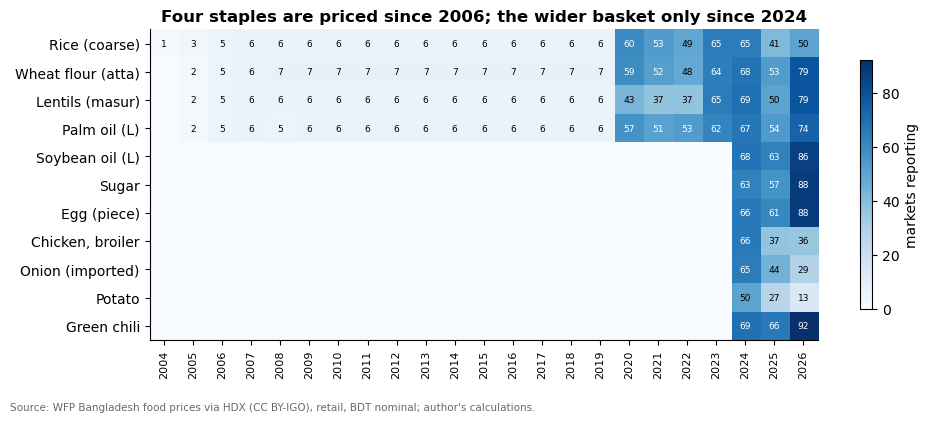

long_basket_markets_2006_2019: 7
core_markets_2025: 66


In [2]:
core = r[r.item.notna()]
cov = core.groupby([core.date.dt.year, "item"]).market.nunique().unstack(0).reindex(list(ITEM_LABEL))
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(cov.fillna(0).values, aspect="auto", cmap="Blues")
ax.set_xticks(range(cov.shape[1])); ax.set_xticklabels(cov.columns, rotation=90, fontsize=8)
ax.set_yticks(range(cov.shape[0])); ax.set_yticklabels([ITEM_LABEL[i] for i in cov.index])
ax.grid(False)
for (i, j), v in np.ndenumerate(cov.values):
    if not np.isnan(v):
        ax.text(j, i, int(v), ha="center", va="center", fontsize=6.5, color="white" if v > 50 else "black")
ax.set_title("Four staples are priced since 2006; the wider basket only since 2024")
fig.colorbar(im, ax=ax, label="markets reporting", shrink=0.8)
save(fig, "fig01_coverage"); plt.show()
fact("long_basket_markets_2006_2019", int(core[(core.date < "2020-01-01")].market.nunique()), "Markets (division level) with long-basket prices before 2020")
fact("core_markets_2025", int(core[core.date.dt.year == 2025].market.nunique()), "Markets with any core item in 2025")

## Prices of the four staples

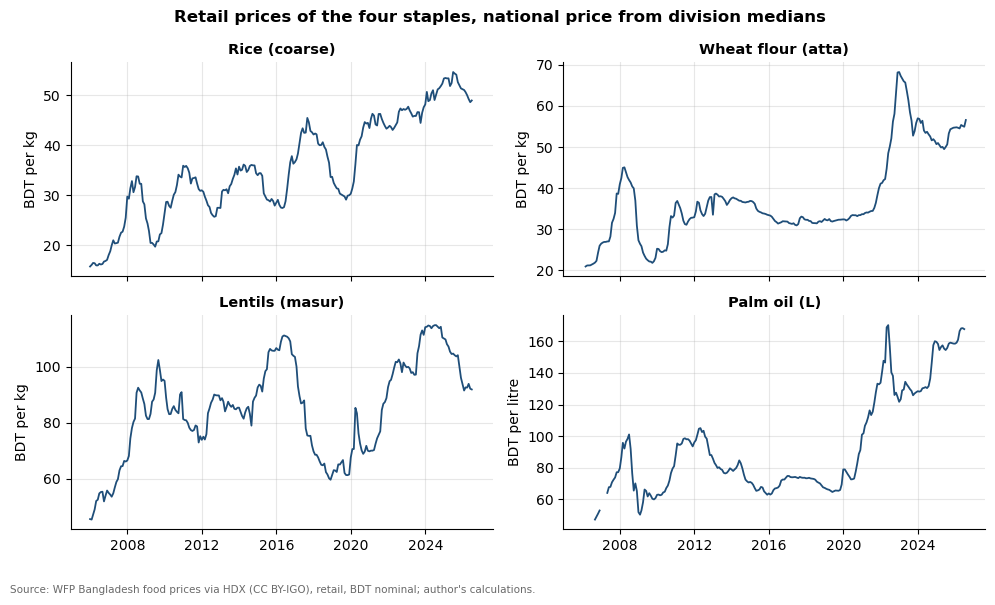

rice_coarse_2016_bdt: 31.1
rice_coarse_latest_bdt: 49.0
atta_2016_bdt: 32.2
atta_latest_bdt: 56.6
lentil_masur_2016_bdt: 108.3
lentil_masur_latest_bdt: 92.0
palm_oil_2016_bdt: 68.1
palm_oil_latest_bdt: 167.8


In [3]:
pl = ix.price_matrix(nat, ix.Q_LONG, "2006-01-01")
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, it in zip(axes.flat, ix.Q_LONG):
    ax.plot(pl.index, pl[it], color=BLUE, lw=1.3)
    ax.set_title(ITEM_LABEL[it], fontsize=10.5)
    ax.set_ylabel("BDT per kg" if it != "palm_oil" else "BDT per litre")
fig.suptitle("Retail prices of the four staples, national price from division medians", fontweight="bold")
save(fig, "fig02_staple_prices"); plt.show()
for it in ix.Q_LONG:
    a, b = pl[it].loc["2016"].mean(), pl[it].dropna().iloc[-1]
    fact(f"{it}_2016_bdt", round(a, 1), "Mean 2016 national price")
    fact(f"{it}_latest_bdt", round(b, 1), f"National price, {str(pl[it].dropna().index[-1].date())[:7]}")

## Two cleaning choices that move the national price

**Cross-division outliers.** The outlier rule in `src/clean.py` compares each price with its own 7-month rolling median, so it misses an error that lasts a whole year. Khulna's coarse rice price is the clear case: 32 to 45 BDT/kg from February to December 2007, while the other five divisions were at 18 to 26 and Khulna itself was back at 28 in January 2008. A second rule now drops a division-month whose price is more than 0.4 log points (about 50% above or 33% below) from the median of all divisions for that item and month. It applies only when at least three divisions report. If half or more of them are that far from the median, there is no consensus price, so the whole item-month is dropped instead. Every dropped row is in `outputs/tables/outliers_cross_section.csv`.

**Divisions entering and leaving.** The national price used to be a plain mean of division medians. When a division stops reporting, that mean jumps even if no price changed. After the cleaning above, rice has 67 months with fewer than six divisions. The national series is now a matched-sample chain: the change from one month to the next is the ratio of mean prices over the divisions that report in both months. When the same divisions report in both months, this is the same as the change in the plain mean. The chained series is then scaled so that, over the latest 12 months in which all divisions report, its average level equals the plain mean. That scaling sets the taka level only; index numbers use price ratios and are unaffected by it. The chart compares the two series for rice.

                                                         count         min  \
rule                             item        division                        
cross_section_abs_log_dev_gt_0.4 onion       Sylhet          3  2026-05-01   
                                 potato      Dhaka           1  2025-03-01   
                                             Rajshahi        6  2025-04-01   
                                             Sylhet          1  2025-04-01   
                                 rice_coarse Khulna         11  2007-02-01   
cross_section_no_consensus       potato      Chattogram      1  2025-02-01   
                                             Dhaka           1  2025-02-01   
                                             Khulna          1  2026-06-01   
                                             Rajshahi        2  2025-02-01   
                                             Sylhet          2  2025-02-01   

                                                               

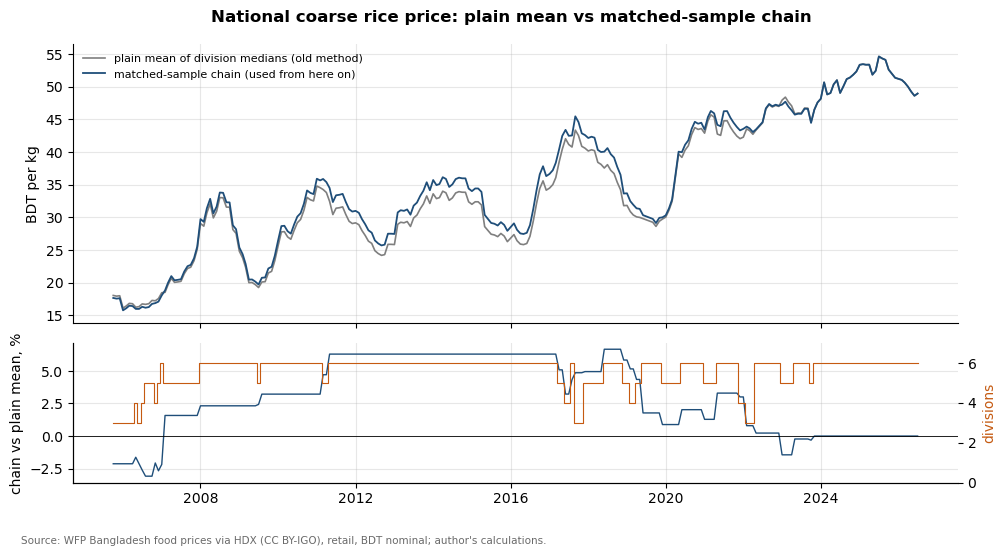

xs_outliers_dropped: 29
rice_chain_vs_mean_max_abs_pct: 6.7
rice_chain_vs_mean_latest_pct: 0.0
rice_months_lt6_divisions: 67


In [4]:
xs = pd.read_csv(TAB / "outliers_cross_section.csv")
print(xs.groupby(["rule", "item", "division"]).date.agg(["count", "min", "max"]))
rn = nat[nat.item == "rice_coarse"].set_index("date")
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax.plot(rn.price_mean_bdt, color=GREY, lw=1.2, label="plain mean of division medians (old method)")
ax.plot(rn.price_bdt, color=BLUE, lw=1.3, label="matched-sample chain (used from here on)")
ax.set_ylabel("BDT per kg"); ax.legend(fontsize=8, loc="upper left")
ax2.plot(100 * (rn.price_bdt / rn.price_mean_bdt - 1), color=BLUE, lw=1)
ax2.axhline(0, color="black", lw=0.6); ax2.set_ylabel("chain vs plain mean, %")
ax2b = ax2.twinx(); ax2b.step(rn.index, rn.n_divisions, color=ORANGE, lw=0.8, where="mid"); ax2b.set_ylabel("divisions", color=ORANGE)
ax2b.grid(False); ax2b.set_ylim(0, 7)
fig.suptitle("National coarse rice price: plain mean vs matched-sample chain", fontweight="bold")
save(fig, "fig02b_national_rice_method"); plt.show()
d = 100 * (rn.price_bdt / rn.price_mean_bdt - 1)
fact("xs_outliers_dropped", len(xs), "Division-months dropped by the cross-division rule (src/clean.py)")
fact("rice_chain_vs_mean_max_abs_pct", round(d.abs().max(), 1), "Largest |chain / plain mean - 1|, coarse rice, %")
fact("rice_chain_vs_mean_latest_pct", round(d.iloc[-1], 1), f"Chain / plain mean - 1, coarse rice, {str(rn.index[-1].date())[:7]}, %")
fact("rice_months_lt6_divisions", int((rn.n_divisions < 6).sum()), "Rice months with fewer than six divisions reporting")

The cross-division rule drops 29 division-months. Eleven are the Khulna rice error (February to December 2007). Eleven more are single potato and onion prices in 2025 and 2026: six of them are Rajshahi reporting the same 62.5 BDT/kg potato price month after month, and three are Sylhet onion at less than half the price elsewhere. The last seven are two potato months (February 2025 and June 2026) where the divisions split into two groups far apart, so the whole month goes. Apart from the Khulna rice error, no long-basket price is dropped. Normal regional differences are far smaller than 0.4 log points: the largest Dhaka gap in notebook 02 is about 7%, and the spread of division index levels in 2025 is about 8%. The rule leaves them alone.

For rice, the chain and the plain mean mostly move together month to month (their monthly changes correlate at about 0.96). Their levels drift apart by up to 6.7% in the stretches when divisions drop out: the gap builds up between 2006 and 2011 and closes again between 2019 and 2023. Because the chain is set equal to the plain mean in the latest year, the drift shows up in the early years: the 2016 average rice price is 31.1 BDT/kg on the chain against 29.3 on the plain mean. That lowers the July 2026 Laspeyres staple index (2016 = 100) from 172.6 to 164.5. The Khulna fix on its own changes only 2007 and leaves the 2026 index level where it was.

The chain has a weakness of its own. If a division leaves while cheap and comes back dear, the change in between is lost. With up to three of six divisions missing in some months, the jumps from divisions entering and leaving look like the bigger risk, so the chain is used everywhere from here on.

## Weights

Base expenditure shares follow from the HIES quantities and base-year prices. Rice dominates, as it does in a poor household's food budget.

In [5]:
W.assign(item=W.item.map(ITEM_LABEL)).round(3)

,basket,item,q0_per_person_month,p0_bdt,share,source
0,long,Rice (coarse),11.163,31.107,0.756,BBS HIES 2016 (Table 5.2 of HIES 2022 Final Re...
1,long,Wheat flour (atta),0.602,32.214,0.042,BBS HIES 2016 (Table 5.2 of HIES 2022 Final Re...
2,long,Lentils (masur),0.298,108.311,0.070,BBS HIES 2016 (Table 5.2 of HIES 2022 Final Re...
3,long,Palm oil (L),0.886,68.066,0.131,BBS HIES 2016 (Table 5.2 of HIES 2022 Final Re...
0,short,Rice (coarse),9.999,53.069,0.451,BBS HIES 2022 Final Report Table 5.2: Rice
1,short,Wheat flour (atta),0.697,51.596,0.031,BBS HIES 2022 Final Report Table 5.2: Wheat
2,short,Lentils (masur),0.361,104.881,0.032,BBS HIES 2022 Final Report Table 5.2: Masoor
3,short,Palm oil (L),0.510,157.303,0.068,BBS HIES 2022 Final Report Table 5.2: Edible o...
4,short,Soybean oil (L),0.510,171.818,0.074,BBS HIES 2022 Final Report Table 5.2: Edible o...
5,short,Sugar,0.460,112.375,0.044,BBS HIES 2022 Final Report Table 5.2: Sugar


## Laspeyres, Paasche, Fisher and chain-linked indices

Laspeyres keeps base quantities. Paasche here assumes households keep their base budget shares and so buy less of what got dearer, which makes it a harmonic mean of price relatives. Fisher is the geometric mean of the two. The chain index resets weights every January.

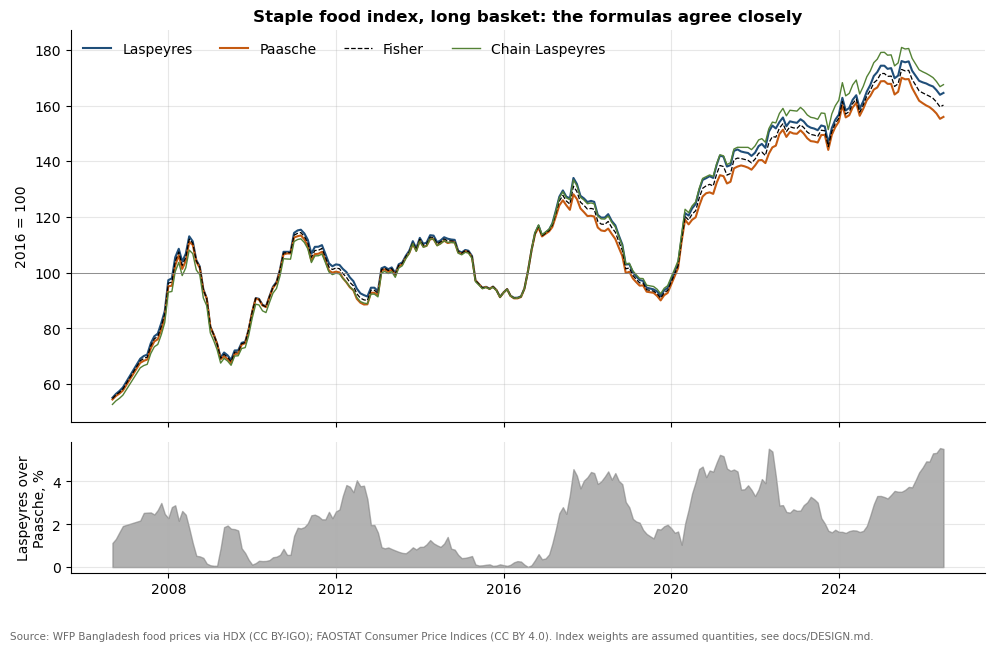

long_index_last_month: 2026-07
long_laspeyres_last: 164.5
long_paasche_last: 155.9
long_fisher_last: 160.2
long_chain_laspeyres_last: 167.5
long_laspeyres_paasche_gap_max_pct: 5.56
long_laspeyres_paasche_gap_max_month: 2026-06
long_laspeyres_2006_09: 55.1


In [6]:
Lv = L.dropna(subset=["laspeyres"])
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(Lv.index, Lv.laspeyres, color=BLUE, label="Laspeyres")
ax.plot(Lv.index, Lv.paasche, color=ORANGE, label="Paasche")
ax.plot(Lv.index, Lv.fisher, color="black", lw=0.9, ls="--", label="Fisher")
ax.plot(Lv.index, Lv.chain_laspeyres, color=GREEN, lw=1, label="Chain Laspeyres")
ax.axhline(100, color=GREY, lw=0.6)
ax.set_ylabel("2016 = 100"); ax.legend(ncol=4, loc="upper left")
ax.set_title("Staple food index, long basket: the formulas agree closely")
gap = 100 * (Lv.laspeyres / Lv.paasche - 1)
ax2.fill_between(gap.index, gap, color=GREY, alpha=0.6)
ax2.set_ylabel("Laspeyres over\nPaasche, %")
save(fig, "fig03_index_formulas", SRC_IDX); plt.show()
last = Lv.index[-1]
fact("long_index_last_month", str(last.date())[:7], "Last month with all four staples")
for c in ["laspeyres", "paasche", "fisher", "chain_laspeyres"]:
    fact(f"long_{c}_last", round(Lv.loc[last, c], 1), "Long basket, 2016 = 100")
fact("long_laspeyres_paasche_gap_max_pct", round(gap.max(), 2), "Max of 100*(L/P - 1)")
fact("long_laspeyres_paasche_gap_max_month", str(gap.idxmax().date())[:7], "Month of max L-P gap")
fact("long_laspeyres_2006_09", round(Lv.laspeyres.iloc[0], 1), "First month, Sep 2006")

## Comparison with the official food CPI

FAOSTAT republishes the BBS consumer price index monthly (2015 = 100). We rebase it to 2016 = 100 and set it against the staple index. The official index covers far more items, including fish, vegetables and meat, so the two should move together over long periods but not month by month.

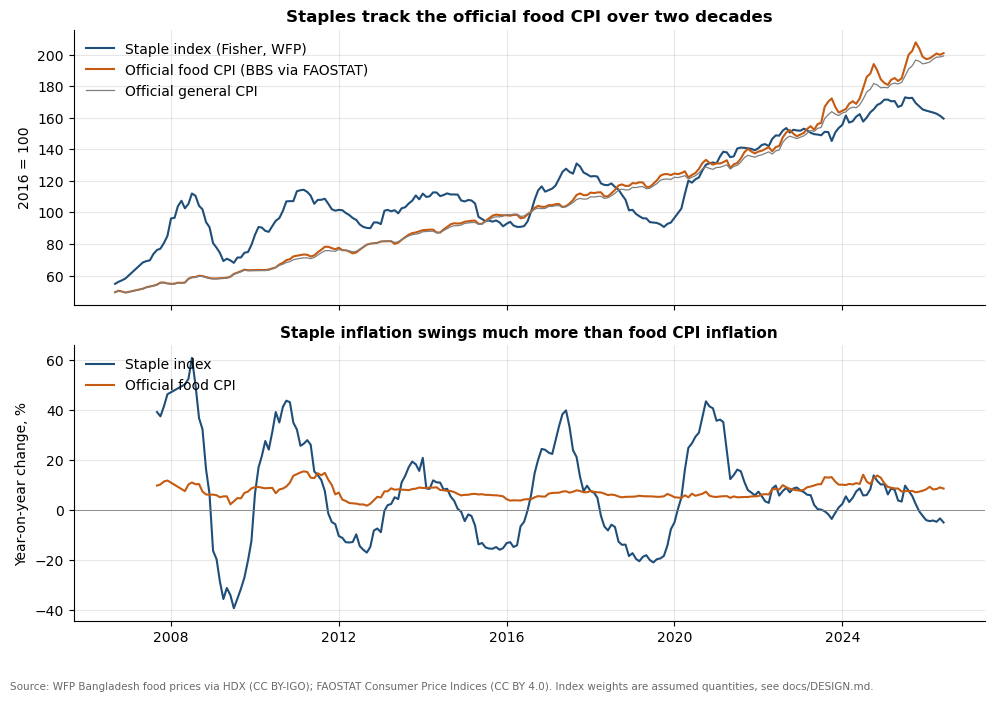

cmp_months: 234
cmp_first_month: 2006-09
cmp_last_month: 2026-06
corr_levels_fisher_cpi_food: 0.903
corr_yoy_fisher_cpi_food: 0.429
sd_yoy_fisher: 19.03
sd_yoy_cpi_food: 2.74
mean_abs_gap_levels_pct: 20.2
gap_levels_last_pct: -20.6
corr_annual_inflation: 0.406


date,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
staple_fisher,-28.0,30.2,13.6,-12.3,8.0,7.9,-11.1,1.2,23.6,-6.0,-18.0,23.8,17.3,7.0,1.9,7.3,5.2
cpi_food,5.5,9.3,13.0,3.4,7.9,7.9,6.1,4.5,7.2,6.2,5.6,5.8,5.3,7.7,10.5,11.5,8.2


In [7]:
cmp = L[["laspeyres", "fisher", "cpi_food_2016", "cpi_general_2016", "fisher_yoy", "cpi_food_2016_yoy"]].dropna(subset=["fisher", "cpi_food_2016"])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
a1.plot(cmp.index, cmp.fisher, color=BLUE, label="Staple index (Fisher, WFP)")
a1.plot(cmp.index, cmp.cpi_food_2016, color=ORANGE, label="Official food CPI (BBS via FAOSTAT)")
a1.plot(cmp.index, cmp.cpi_general_2016, color=GREY, lw=0.9, label="Official general CPI")
a1.set_ylabel("2016 = 100"); a1.legend(loc="upper left")
a1.set_title("Staples track the official food CPI over two decades")
y = cmp.dropna(subset=["fisher_yoy", "cpi_food_2016_yoy"])
a2.plot(y.index, y.fisher_yoy, color=BLUE, label="Staple index")
a2.plot(y.index, y.cpi_food_2016_yoy, color=ORANGE, label="Official food CPI")
a2.axhline(0, color=GREY, lw=0.6)
a2.set_ylabel("Year-on-year change, %"); a2.legend(loc="upper left")
a2.set_title("Staple inflation swings much more than food CPI inflation", fontsize=11)
save(fig, "fig04_vs_official_cpi", SRC_IDX); plt.show()
fact("cmp_months", len(cmp), "Months with both staple Fisher index and official food CPI")
fact("cmp_first_month", str(cmp.index[0].date())[:7], "First month of overlap")
fact("cmp_last_month", str(cmp.index[-1].date())[:7], "Last month of overlap")
fact("corr_levels_fisher_cpi_food", round(cmp.fisher.corr(cmp.cpi_food_2016), 3), "Pearson r, index levels (both trend up, so high by construction)")
fact("corr_yoy_fisher_cpi_food", round(y.fisher_yoy.corr(y.cpi_food_2016_yoy), 3), "Pearson r, year-on-year % changes")
fact("sd_yoy_fisher", round(y.fisher_yoy.std(), 2), "SD of staple y/y inflation, pp")
fact("sd_yoy_cpi_food", round(y.cpi_food_2016_yoy.std(), 2), "SD of official food y/y inflation, pp")
gap_lv = 100 * (cmp.fisher / cmp.cpi_food_2016 - 1)
fact("mean_abs_gap_levels_pct", round(gap_lv.abs().mean(), 1), "Mean |Fisher/CPI_food - 1|, %")
fact("gap_levels_last_pct", round(gap_lv.iloc[-1], 1), f"Fisher/CPI_food - 1 in {str(cmp.index[-1].date())[:7]}, %")
full = cmp.groupby(cmp.index.year).fisher.transform("size") == 12
ann = cmp[full].resample("YS").mean().dropna()
annual = pd.DataFrame({"staple_fisher": ann.fisher, "cpi_food": ann.cpi_food_2016})
annual = (100 * annual.pct_change()).dropna().round(1)
annual.index = annual.index.year
annual.to_csv(TAB / "annual_inflation_staples_vs_cpi.csv")
fact("corr_annual_inflation", round(annual.staple_fisher.corr(annual.cpi_food), 3), "Pearson r, annual average inflation, full calendar years only")
annual.T

Lead-lag check: does staple inflation run ahead of official food inflation? We correlate the staple y/y change at month t with food CPI y/y change at t + k.

In [8]:
lags = pd.Series({k: y.fisher_yoy.corr(y.cpi_food_2016_yoy.shift(-k)) for k in range(-6, 7)})
print(lags.round(3))
fact("best_lead_months", int(lags.idxmax()), "k maximising corr(staple y/y_t, CPI food y/y_{t+k}); positive = staples lead")
fact("best_lead_corr", round(lags.max(), 3), "Correlation at that lead")

-6    0.094
-5    0.183
-4    0.256
-3    0.319
-2    0.362
-1    0.406
 0    0.429
 1    0.438
 2    0.436
 3    0.414
 4    0.385
 5    0.358
 6    0.310
dtype: float64
best_lead_months: 1
best_lead_corr: 0.438


## Divisional indices

Each division's Laspeyres index uses national 2016 prices as the base, so the level shows both price change and how dear the division is relative to the country. Rangpur is counted with Rajshahi and Mymensingh with Dhaka, because those divisions were split off later and the pre-2020 data use the old boundaries.

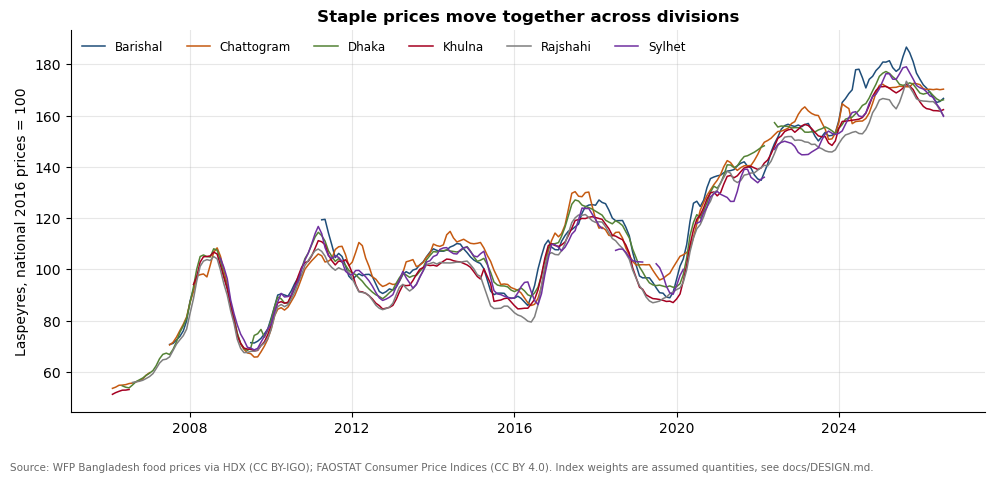

division_spread_2016_pct: 8.5
division_spread_2025_pct: 7.8
division_dearest_2025: Barishal
division_cheapest_2025: Rajshahi
division_yoy_mean_pairwise_corr: 0.92


date,2006-01-01,2007-01-01,2008-01-01,2009-01-01,2010-01-01,2011-01-01,2012-01-01,2013-01-01,2014-01-01,2015-01-01,...,2017-01-01,2018-01-01,2019-01-01,2020-01-01,2021-01-01,2022-01-01,2023-01-01,2024-01-01,2025-01-01,2026-01-01
division,,,,,,,,,,,,,,,,,,,,,
Barishal,NaN,75.4,97.8,74.0,92.1,107.2,95.0,100.5,107.6,93.3,...,118.4,118.0,93.3,123.2,138.8,149.7,153.8,173.2,180.3,168.0
Chattogram,55.9,76.5,99.2,70.2,91.1,104.8,100.1,101.7,111.3,100.1,...,124.2,111.2,99.6,119.3,140.7,153.5,157.8,162.2,171.5,170.2
Dhaka,56.2,70.5,101.3,73.6,94.6,106.4,92.3,99.5,107.2,96.9,...,121.7,116.0,94.8,117.9,141.5,154.4,153.9,164.1,173.5,167.6
Khulna,52.3,NaN,100.1,71.5,93.6,105.4,88.0,96.6,102.4,91.5,...,116.5,111.2,88.9,116.3,137.0,149.2,153.0,161.7,170.0,162.3
Rajshahi,56.7,68.4,98.3,70.4,92.4,102.4,87.7,96.0,102.4,88.1,...,116.4,109.6,89.6,114.4,136.2,146.9,147.8,156.0,167.2,164.0
Sylhet,NaN,NaN,98.1,73.4,94.6,106.2,93.2,97.7,107.3,95.4,...,115.9,108.1,97.0,118.9,132.8,145.9,149.4,161.9,175.3,165.9


In [9]:
dv = D.pivot(index="date", columns="division", values="laspeyres_natbase")
fig, ax = plt.subplots(figsize=(10, 4.8))
cols = [BLUE, ORANGE, GREEN, RED, GREY, "#7030a0"]
for c, col in zip(dv.columns, cols):
    s = dv[c].rolling(3, min_periods=2).mean()
    ax.plot(s.index, s, color=col, lw=1.1, label=c)
ax.set_ylabel("Laspeyres, national 2016 prices = 100"); ax.legend(ncol=6, loc="upper left", fontsize=8.5)
ax.set_title("Staple prices move together across divisions")
save(fig, "fig05_division_indices", SRC_IDX); plt.show()
yr = dv.resample("YS").mean()
spread = (yr.max(axis=1) / yr.min(axis=1) - 1) * 100
fact("division_spread_2016_pct", round(spread.loc["2016"].iloc[0], 1), "Max/min division index, 2016 average, %")
fact("division_spread_2025_pct", round(spread.loc["2025"].iloc[0], 1), "Max/min division index, 2025 average, %")
fact("division_dearest_2025", yr.loc["2025"].iloc[0].idxmax(), "Highest 2025 average index")
fact("division_cheapest_2025", yr.loc["2025"].iloc[0].idxmin(), "Lowest 2025 average index")
dyoy = 100 * (dv / dv.shift(12) - 1)
fact("division_yoy_mean_pairwise_corr", round(dyoy.corr().values[np.triu_indices(dv.shape[1], 1)].mean(), 3), "Mean pairwise correlation of division y/y changes")
yr.round(1).T

## Wide basket, 2024 to 2026

With eleven items the basket is closer to what a household buys. The base is the 2025 average.

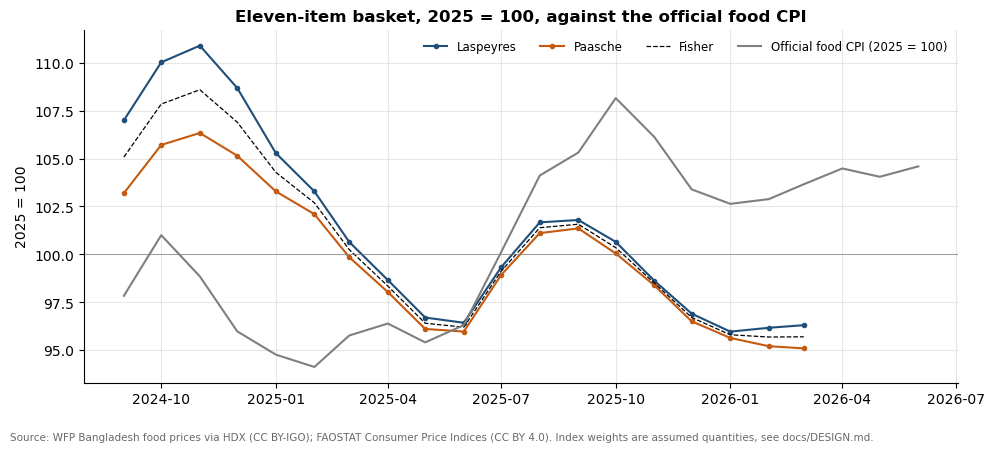

wide_months: 19
wide_first_month: 2024-09
wide_last_month: 2026-03
wide_lp_gap_mean_pct: 1.38
long_lp_gap_mean_pct_same_months: 3.6


In [10]:
Sv = S.dropna(subset=["laspeyres"])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(Sv.index, Sv.laspeyres, color=BLUE, marker="o", ms=3, label="Laspeyres")
ax.plot(Sv.index, Sv.paasche, color=ORANGE, marker="o", ms=3, label="Paasche")
ax.plot(Sv.index, Sv.fisher, color="black", ls="--", lw=0.9, label="Fisher")
fao = S.cpi_food_2015.dropna()
fao = fao / fao.loc["2025"].mean() * 100
ax.plot(fao.loc["2024-09":].index, fao.loc["2024-09":], color=GREY, lw=1.5, label="Official food CPI (2025 = 100)")
ax.axhline(100, color=GREY, lw=0.5)
ax.set_ylabel("2025 = 100"); ax.legend(ncol=4, loc="upper right", fontsize=8.5)
ax.set_title("Eleven-item basket, 2025 = 100, against the official food CPI")
save(fig, "fig06_wide_basket", SRC_IDX); plt.show()
g2 = 100 * (Sv.laspeyres / Sv.paasche - 1)
fact("wide_months", len(Sv), "Months with all 11 items")
fact("wide_first_month", str(Sv.index[0].date())[:7], "First month")
fact("wide_last_month", str(Sv.index[-1].date())[:7], "Last month")
fact("wide_lp_gap_mean_pct", round(g2.mean(), 2), "Mean 100*(L/P - 1), wide basket")
fact("long_lp_gap_mean_pct_same_months", round((100 * (L.laspeyres / L.paasche - 1)).loc[Sv.index].mean(), 2), "Same months, long basket (2016 base, so a ten-year-old base widens the gap)")

## Item contributions to the change in the staple index, 2016 to latest

Laspeyres contribution of item i = w_i0 (p_it / p_i0 - 1) x 100, which adds up to the index change.

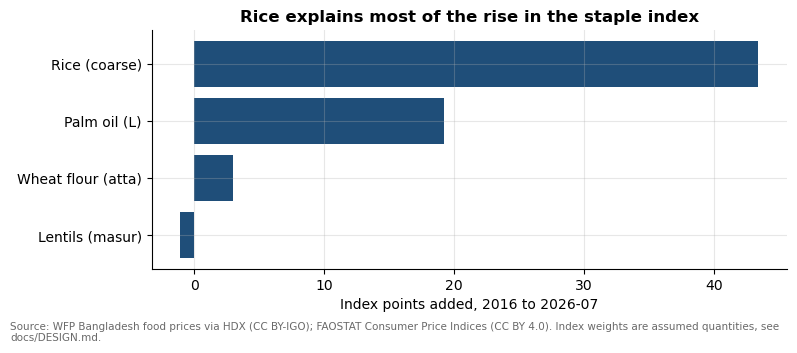

contrib_lentil_masur_pts: -1.1
contrib_atta_pts: 3.0
contrib_palm_oil_pts: 19.2
contrib_rice_coarse_pts: 43.4
rice_share_of_change: 0.672


In [11]:
p0 = pl.loc["2016"].mean(); w = W[W.basket == "long"].set_index("item").share
pt = pl.loc[last]
contrib = (w * (pt / p0 - 1) * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh([ITEM_LABEL[i] for i in contrib.index], contrib.values, color=BLUE)
ax.set_xlabel(f"Index points added, 2016 to {str(last.date())[:7]}")
ax.set_title("Rice explains most of the rise in the staple index")
save(fig, "fig07_contributions", SRC_IDX); plt.show()
for i, v in contrib.items():
    fact(f"contrib_{i}_pts", round(v, 1), "Laspeyres contribution, index points")
fact("rice_share_of_change", round(contrib["rice_coarse"] / contrib.sum(), 3), "Rice contribution / total change")

## Sensitivity to the weights

The HIES quantities are survey averages and a few conversions are assumed, so we redraw them 500 times, scaling each item by a random factor between 0.5 and 1.5, and see how much the latest Laspeyres level and the y/y correlation with the official CPI move.

In [12]:
rng = np.random.default_rng(173)
res = []
for _ in range(500):
    q = {k: v * rng.uniform(0.5, 1.5) for k, v in ix.Q_LONG.items()}
    out, _, _ = ix.lpf(pl, q, ix.BASE_LONG)
    yy = ix.yoy(out.fisher)
    res.append({"last": out.laspeyres.dropna().iloc[-1], "corr": yy.corr(L.cpi_food_2016_yoy)})
res = pd.DataFrame(res)
print(res.describe().round(3))
fact("sens_last_laspeyres_p05", round(res["last"].quantile(0.05), 1), "5th percentile over 500 random weight draws")
fact("sens_last_laspeyres_p95", round(res["last"].quantile(0.95), 1), "95th percentile")
fact("sens_corr_yoy_p05", round(res["corr"].quantile(0.05), 3), "5th percentile of y/y correlation with food CPI")
fact("sens_corr_yoy_p95", round(res["corr"].quantile(0.95), 3), "95th percentile")

          last     corr
count  500.000  500.000
mean   164.875    0.429
std      4.147    0.005
min    156.284    0.418
25%    161.863    0.426
50%    164.793    0.429
75%    167.373    0.432
max    178.731    0.443
sens_last_laspeyres_p05: 158.2
sens_last_laspeyres_p95: 172.2
sens_corr_yoy_p05: 0.421
sens_corr_yoy_p95: 0.437


In [13]:
pd.DataFrame(facts).to_csv(TAB / "key_facts_indices.csv", index=False)
L.reset_index().to_csv(TAB / "indices_long_monthly.csv", index=False)
print(len(facts), "facts saved")

59 facts saved
